 # HW3: Unsupervised Learning - Clustering, TF-IDF & Dimensionality Reduction

In this assignment you will build intuition for unsupervised learning from the ground up and
then apply it to real text data. You will:

1. Implement the K-Means assignment & update steps from scratch in NumPy.
2. Compute TF-IDF by hand on a toy corpus to see what the formula rewards and penalizes.
3. Build a text clustering pipeline with `TfidfVectorizer` + `KMeans` on the 20 Newsgroups dataset.
4. Interpret clusters from their centroids' top terms.
5. Reduce the data to 2D with **PCA** and **UMAP** and explain why they look different.
6. Compare your clusters against the true categories and reason about which get confused and why.

Fill in every cell marked **`TODO`** and answer every **Markdown** question cell. Run the notebook
top-to-bottom before submitting so all outputs (tables, plots) are visible.

**Cell tags.** Every actionable cell is tagged so you know what it expects:
- `[WRITE CODE]` - a blank code cell for you to fill in.
- `[RUN ONLY]` - provided code; just run it (nothing to edit or answer).
- `[ANSWER]` - a question cell; type your response where it says *(Your answer here.)*.
- `[REQUIRED]` - a cell you must complete (your info, disclosures, and work-history link); omitting these carries grade penalties - see **Submission requirements**.

A `[WRITE CODE]` or `[RUN ONLY]` cell followed by an `[ANSWER]` cell means: do that cell, then answer the question about its output.

**[REQUIRED]**

## Student information & disclosures

| | |
|---|---|
| **Name** | Elizabeth Horishny |
| **Student ID** | 117578447 |
| **Work format** | Individual |

**External source disclosure.** Cite every external source you used and what you got from each one,
including textbooks, websites, Stack Overflow answers, library documentation, YouTube videos, and
forum posts.
- https://numpy.org/doc/stable/user/basics.broadcasting.html | to understand what 'numpy broadcasting' entails
- https://stackoverflow.com/questions/16815928/what-does-mean-on-numpy-arrays | not familiar with [:,:] syntax
- https://www.geeksforgeeks.org/python/calculate-the-euclidean-distance-using-numpy/ euclidean distance numpy
- https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html more info about the above
- https://stackoverflow.com/questions/17936587/in-numpy-find-euclidean-distance-between-each-pair-from-two-arrays another euclidean distance numpy example
- https://en.moonbooks.org/Articles/How-to-create-a-distance-matrix-from-two-numpy-arrays-of-points-/ how to properly use np.argmin in this context
- https://www.w3schools.com/python/python_for_loops.asp i barely know numpy let alone how to do a python for loop XD
- https://stackoverflow.com/questions/25438420/indexes-of-elements-in-numpy-array-that-satisfy-conditions-on-the-value-and-the how to get all indices of an array that match a condition
- https://numpy.org/doc/stable/reference/generated/numpy.mean.html mean of all values in np array
- https://www.geeksforgeeks.org/python/python-boolean-array-in-numpy/  to "normalize" 0 or 1 values only
- https://www.geeksforgeeks.org/machine-learning/understanding-tf-idf-term-frequency-inverse-document-frequency/ , https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html guides for tFIdfVectorizer
- https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html,https://realpython.com/k-means-clustering-python/ sklearn KMeans resources
- https://www.geeksforgeeks.org/python/numpy-argsort-in-python/ argsort resources
- https://www.geeksforgeeks.org/python/matplotlib-pyplot-colorbar-function-in-python/ matplotlib colorbar

**AI usage disclosure.** Describe how you used AI tools (e.g., ChatGPT, Claude, Copilot), if at all,
and for which parts of the assignment. Any use of AI tools must comply with the course AI policy.

*[YOUR AI DISCLOSURE HERE. Write "none" only if you truly used none.]*

**[REQUIRED]**

## Work history link

Paste **one** of the following here (see **Required items** below for the rules):

* a **Google Colab** share link ("Anyone with the link", **Editor** permission), or
* a **public GitHub repository** URL with an incremental commit history.

https://colab.research.google.com/drive/1I_vzWfUuejqZ5yccGOB0M2z-qguyfhJe?usp=sharing

## Submission requirements

Submit (1) your completed notebook `HW3_[LASTNAME]_[STUDENTID].ipynb`, run top-to-bottom with all
outputs visible, and (2) a PDF export of the same notebook.

### Required items (must be included in the notebook)

The following items are required and will result in grade deductions if omitted:

* **Work history** *(automatic -30% deduction from the total assignment grade if omitted)*
    * **Option A - Google Colab:** Share the live notebook link using the "Anyone with the link"
      setting with **Editor** permissions, and submit it along with a printed PDF of the notebook.
    * **Option B - GitHub:** Alternatively, host your code in a **public** repository with a
      visible, incremental commit history.
    * **Authentic timeline:** Your version or commit history must reflect step-by-step progress;
      pasting a fully completed project into a blank file at the end will result in the automatic
      loss of this credit.
* **Source citations** *(automatic -30% deduction from the total assignment grade if omitted)*
    * Complete the **External Source Disclosure** at the top of the notebook.
    * Cite every external source used and what you got from each one, including textbooks, websites,
      Stack Overflow answers, library documentation, YouTube videos, and forum posts.
    * Write "none" only if you truly used none.
* **AI usage disclosure** *(automatic -30% deduction from the total assignment grade if omitted)*
    * Complete the **AI Usage Disclosure** at the top of the notebook, describing how AI tools
      (e.g., ChatGPT, Claude, Copilot) were used.
    * Any use of AI tools must comply with the course AI policy.

## Setup

Colab doesn't include UMAP, so run the install cell once. If `import umap` errors right after
installing, use Runtime > Restart session and run the notebook again from the top. **Keep the
random seed as given** - this keeps your clusters and plots reproducible from run to run.

In [1]:
# [RUN ONLY]
# Colab doesn't ship umap-learn, so install it (run once).
# pip may print a harmless warning about pytensor/numba versions - you can ignore it;
# this notebook never imports pytensor. If 'import umap' later errors, use
# Runtime > Restart session and run again from the top.
!pip install -q umap-learn

In [2]:
# [RUN ONLY]
# Cap threads BEFORE importing numpy so K-Means is bit-for-bit reproducible
# (parallel floating-point reductions are otherwise order-dependent).
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Fix the seed EVERYWHERE for reproducible clusters/plots.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


# Part 1 - Conceptual "From-Scratch" Warm-up  *(15-20%)*

Before using any library, you'll implement the two core steps of K-Means yourself and compute
TF-IDF by hand.

### TODO 1 - K-Means from scratch (NumPy, synthetic 2D data)

We generate 4 blobs in 2D. Implement the two core steps:

* `assign_clusters(X, centroids)` → for each point, the index of the nearest centroid (L2).
* `update_centroids(X, labels, k)` → the mean of the points assigned to each cluster.

**`assign_clusters` must be vectorized.** Compute all point-to-centroid distances with NumPy
broadcasting (see the hint in the code cell) - a Python `for`-loop over the data points is **not**
acceptable and will lose credit, even if it produces the right answer.

**Convergence criterion for this assignment: run a fixed 10 iterations** (no tolerance test). The driver cell below is provided; it calls your two functions and animates the centroid movement.

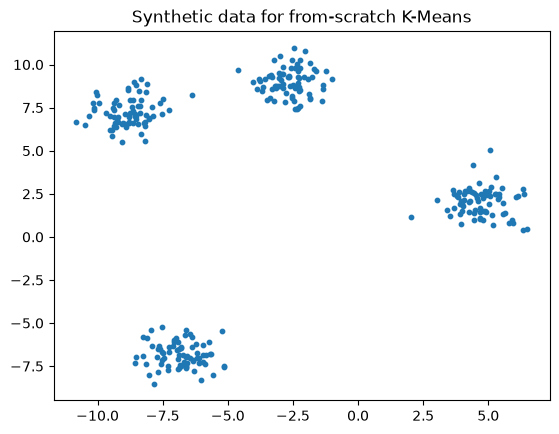

In [3]:
# [RUN ONLY]
from sklearn.datasets import make_blobs
X_blobs, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.80,
                        random_state=RANDOM_STATE)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=10)
plt.title('Synthetic data for from-scratch K-Means'); plt.show()
# print(X_blobs, 'this is what X look like')


In [4]:
# [WRITE CODE]
def assign_clusters(X, centroids):
    """Return an array `labels` (N,) where labels[i] = index of nearest centroid to X[i]."""
    sub = X[:,None,:]- centroids[None,:,:]
    sqr = sub**2

    print("1)",sub)
    print('sqr', sqr)

    # norm = np.linalg.norm(X-centroids)
    sum = sqr.sum(-1)

    print('sum', sum)
    distances = np.sqrt(sum)
    print('sqrt', distances)
    labels = np.argmin(distances, axis=1)
    print('min', labels)
    return labels


#####################################################################
# TODO:                                          https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html                   #
# For each point in X, find the index of the closest centroid (L2 distance).       #straight line distance btwn 2 points in space
# Return `labels`, shape (N,).                                                      # centroids and X are list of 2D points
# REQUIRED: vectorize this with NumPy broadcasting - do NOT use a Python loop over  #
# the points (a loop will lose credit even if the output is correct).              #
# Hint: broadcasting X[:, None, :] - centroids[None, :, :] gives (N, K, D).         # (indexes of nearest centroids, # of centroids, distances?
# np.linalg.norm()
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################
# centroids=np.array([[0,0], [2,2]])
# X=np.array([[0,1], [1,2], [3,3]])
# labels = assign_clusters(X, centroids)

In [5]:
# [WRITE CODE]
def update_centroids(X, labels, k):
    """Return new centroids (k, D): the mean of the points in each cluster."""
    #####################################################################
    # TODO:                                                             #
    # For each cluster j in 0..k-1, set new_centroids[j] to the mean of the points      #
    print(X)
    new_centroids = np.zeros(shape=(k,2))
    for j in range(k):
      relevants_indices = np.where(labels == j)[0]
      print(j, ":", relevants_indices)
      relevant_points = X[relevants_indices]
      print('relevant pnts', relevant_points)
      mean = np.mean( relevant_points,axis=0)
      print('mean', mean)
      if not np.isnan(mean[0]):
        new_centroids[j] =mean
      print('new cent', new_centroids)
    return new_centroids
  # printrelevant_points.take(relevant_indices)


# assigned to it. Guard against empty clusters (leave their row unchanged / zeros). #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################
# update_centroids(X,labels,4)

this is what centroids looks like [[-4.0442146   8.99307503]
 [-9.29974482  7.9278359 ]
 [-7.93581376 -5.41494258]
 [ 5.29752696  3.49060407]]
1) [[[ -5.16160188  -2.34942761]
  [  0.09392834  -1.28418848]
  [ -1.27000272  12.05859   ]
  [-14.50334344   3.15304335]]

 [[ -5.48244385  -1.97719655]
  [ -0.22691363  -0.91195742]
  [ -1.59084469  12.43082106]
  [-14.82418541   3.52527441]]

 [[  2.1930529   -0.95546382]
  [  7.44858313   0.10977531]
  [  6.08465206  13.45255379]
  [ -7.14868866   4.54700714]]

 ...

 [[  0.24903038   0.16891819]
  [  5.50456061   1.23415732]
  [  4.14062955  14.5769358 ]
  [ -9.09271117   5.67138914]]

 [[ -4.77937846  -0.32840226]
  [  0.47615177   0.73683687]
  [ -0.8877793   14.07961535]
  [-14.12112002   5.1740687 ]]

 [[ -4.09842843  -0.58504183]
  [  1.1571018    0.48019731]
  [ -0.20682926  13.82297578]
  [-13.44016998   4.91742913]]]
sqr [[[2.66421340e+01 5.51981008e+00]
  [8.82253396e-03 1.64914004e+00]
  [1.61290691e+00 1.45409593e+02]
  [2.10346

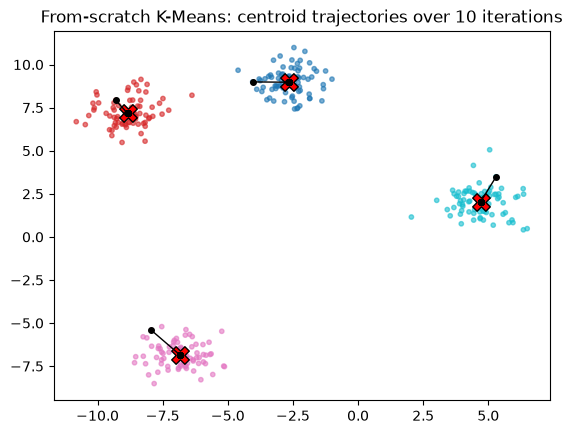

Part 1 TODO 1 checkpoint passed.


In [6]:
# [RUN ONLY]
# Provided driver: 10 fixed iterations, calls YOUR functions, shows centroid movement.
k = 4
rng = np.random.default_rng(RANDOM_STATE)
centroids = X_blobs[rng.choice(len(X_blobs), k, replace=False)].copy()
print('this is what centroids looks like', centroids)
history = [centroids.copy()]
for _ in range(10):
    labels = assign_clusters(X_blobs, centroids)
    centroids = update_centroids(X_blobs, labels, k)
    print(centroids, 'centroids bro!')
    history.append(centroids.copy())

plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='tab10', s=10, alpha=0.6)
hist = np.array(history)
for j in range(k):
    plt.plot(hist[:, j, 0], hist[:, j, 1], '-o', color='black', markersize=4, linewidth=1)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=160, edgecolor='k')
plt.title('From-scratch K-Means: centroid trajectories over 10 iterations'); plt.show()

# Light sanity checkpoint
assert labels.shape == (len(X_blobs),), 'labels should be shape (N,)'
assert centroids.shape == (k, 2), 'centroids should be shape (k, 2)'
print('Part 1 TODO 1 checkpoint passed.')


### TODO 2 - TF-IDF by hand (no sklearn)

A 3-sentence toy corpus is provided. Some words appear in all three sentences, some in only one -
so the idf term has visible effects. Using the convention
$\mathrm{tf}(t,d)=\text{count of }t\text{ in }d$, $\mathrm{idf}(t)=\ln\!\frac{N}{\mathrm{df}(t)}$, and $\mathrm{tfidf}=\mathrm{tf}\cdot\mathrm{idf}$ (natural log, $N=3$, no smoothing), fill in `df`, `idf`, and `tfidf`.

In [7]:
# [RUN ONLY]
corpus = [
    'the cat sat on the mat',
    'the dog sat on the log',
    'the cat chased the dog',
]
tokens = [doc.split() for doc in corpus]
vocab = sorted({w for doc in tokens for w in doc})
N = len(corpus)

# term-frequency (raw counts) matrix, shape (N, V) -- provided
tf = np.array([[doc.count(w) for w in vocab] for doc in tokens], dtype=float)
print('vocab:', vocab)
pd.DataFrame(tf, columns=vocab, index=['doc1', 'doc2', 'doc3']).astype(int)


vocab: ['cat', 'chased', 'dog', 'log', 'mat', 'on', 'sat', 'the']


,cat,chased,dog,log,mat,on,sat,the
doc1,1,0,0,0,1,1,1,2
doc2,0,0,1,1,0,1,1,2
doc3,1,1,1,0,0,0,0,2


In [8]:
# [WRITE CODE]
# df: how many documents contain each term (shape (V,))

#####################################################################
# TODO:                                                             #
# 1. df    = number of documents containing each term           -> shape (V,)       #
booldf = np.where(tf > 0,1,0)
df = np.sum(booldf, axis=0)
# print('df', df)
# 2. idf   = np.log(N / df)                                      -> shape (V,)       #
idf = np.log(len(vocab)/ df)

# print('idf', idf)
# 3. tfidf = tf * idf  (broadcast idf across the rows)           -> shape (N, V)     #
tfidf = tf * idf

# print('tfidf', tfidf)
# Then display df/idf and the tf-idf matrix as labeled tables.
print(pd.DataFrame(np.array([df, idf]), columns=vocab, index=['df', 'idf'])) #.astype(int)
print(pd.DataFrame(tfidf, columns=vocab, index=['doc1', 'doc2', 'doc3']))                 #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


          cat    chased       dog       log       mat        on       sat  \
df   2.000000  1.000000  2.000000  1.000000  1.000000  2.000000  2.000000   
idf  1.386294  2.079442  1.386294  2.079442  2.079442  1.386294  1.386294   

          the  
df   3.000000  
idf  0.980829  
           cat    chased       dog       log       mat        on       sat  \
doc1  1.386294  0.000000  0.000000  0.000000  2.079442  1.386294  1.386294   
doc2  0.000000  0.000000  1.386294  2.079442  0.000000  1.386294  1.386294   
doc3  1.386294  2.079442  1.386294  0.000000  0.000000  0.000000  0.000000   

           the  
doc1  1.961659  
doc2  1.961659  
doc3  1.961659  


**[ANSWER]**

### Question 1.1 - idf intuition

Which word has the smallest tf-idf everywhere, and why does the formula do that?

- "the" has the smallest idf because it is in all three documents and is therefore the least unique word. We attach less weight to common words in order to bring attention to rarer words during text clustering.

# Part 2 - Text Processing & Clustering on Benchmark Data  *(40%)*

Now we move to real text: a 4-category subset of **20 Newsgroups**. The first run downloads the
dataset (~a few MB), so the load cell may pause the first time.

### Dataset

We load the **full** `subset='all'` split for four categories. Using `subset='all'`
(train + test) gives more documents and steadier clusters. The categories were chosen so
each has reasonably distinctive vocabulary.

In [9]:
# [RUN ONLY]
from sklearn.datasets import fetch_20newsgroups

categories = ["comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "rec.autos"]
# remove=('headers','footers','quotes') is ESSENTIAL: without it K-Means clusters on
# email signatures / quoted headers instead of topic content.
news = fetch_20newsgroups(subset='all', categories=categories,
                          remove=('headers', 'footers', 'quotes'),
                          random_state=RANDOM_STATE)

documents = np.array(news.data, dtype=object)
true_labels = np.array(news.target)
target_names = news.target_names
print(f'{len(documents)} documents across {len(target_names)} categories:')
print(target_names)


3944 documents across 4 categories:
['comp.graphics', 'rec.autos', 'rec.sport.baseball', 'sci.space']


### TODO 3 - TF-IDF vectorize the corpus

Fit a `TfidfVectorizer` with English stop-words removed and the vocabulary capped at 5000 terms
(keeps it fast and the centroids interpretable). Print the resulting matrix shape.

### Vocabulary pruning: `min_df` and `max_df`

Beyond stop-words and the 5000-term cap, we drop terms that are too rare or too common:
`min_df=3` ignores terms appearing in fewer than 3 documents (kills typos / one-off tokens),
and `max_df=0.8` ignores terms appearing in more than 80% of documents (near-ubiquitous words
that, like stop-words, carry little signal). Both make the TF-IDF space cleaner and the
clusters more interpretable.

In [10]:
# [WRITE CODE]
# print(documents, 'DOCS')
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000, min_df=3, max_df=.8 )
X = vectorizer.fit_transform(documents)
# print(X)
print(X.shape)
#####################################################################
# TODO:                                                             #
# Fit a TfidfVectorizer on `documents` with:                                        #
#   stop_words='english', max_features=5000, min_df=3, max_df=0.8                    #
# Store the sparse matrix in X and print X.shape.                                   #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


(3944, 5000)


**[ANSWER]**

### Question 2.1 - Understanding the TF-IDF matrix

Run the cell above and answer from the printed shape:

* What is the shape of `X`?
**(3944,5000)**
* What does each row, `X[i, :]`, represent?
**A tuple of (Document Index, Word Index). In other words, which document the word is in, and how far into the document the word appears.**
* What does each column, `X[:, j]`, represent?
**The tf-idf values for the terms included.**
* What does an individual value, `X[i, j]`, represent?
**The tf-idf value of word with respect to the document (tuple value 0) as well as its position within the document (tuple value 1). the same word can appear in the same document and/or the same position within the document and get far different tf-idf values.**
* What does it mean when `X[i, j]` is zero?
**The word does not appear in any documents.**


In [11]:
# [RUN ONLY]
# Inspect two fixed documents (Doc 0 and Doc 3).
terms = vectorizer.get_feature_names_out()

def inspect_document(doc_idx, n=5):
    row = np.asarray(X[doc_idx].todense()).ravel()
    top = row.argsort()[::-1][:n]
    print(f"Doc {doc_idx}  |  category = {target_names[true_labels[doc_idx]]}")
    print("Top TF-IDF terms:", [(terms[j], round(float(row[j]), 3)) for j in top])
    print("Snippet:", repr(documents[doc_idx][:500]))
    print()

inspect_document(0)
inspect_document(3)

Doc 0  |  category = sci.space
Top TF-IDF terms: [('page', 0.274), ('text', 0.253), ('catalogue', 0.238), ('subject', 0.214), ('ch', 0.198)]
Snippet: "\nDo you know of the world-wide-web?  This is a global hypertext (well, \nhypermedia) network running on the internet.  One of the nice things\nabout it is that is understands and incorporates virtually all of the\nother systems being used, like WAIS, Gopher, FTP, Archie, etc.  It\nis usually quite easy to add existing resources to the web.\n\nIf you'd like to explore, I'd suggest getting the XMosaic program,\nwritten at the NCSA.  It's an X-windows web browser, and is pretty\nslick.  It can understand a"

Doc 3  |  category = rec.sport.baseball
Top TF-IDF terms: [('miller', 0.318), ('mound', 0.301), ('muscle', 0.298), ('twins', 0.274), ('pulled', 0.272)]
Snippet: 'Dunno about Miller.\n\nIf you mean Scott Erickson, currently the reigning Twins Least Consistent\nGood Player, he pulled a muscle in the neighborhood of the rib cage that\nmad

**[ANSWER]**

### Question 2.2 - Inspecting one document's TF-IDF

The cell above inspects two fixed documents, **Doc 0** and **Doc 3**. Answer for these two documents:

* List **Doc 0**'s five highest-TF-IDF terms and their scores (copy them from the output above).
**Doc 0 Top TF-IDF terms: [('page', 0.274), ('text', 0.253), ('catalogue', 0.238), ('subject', 0.214), ('ch', 0.198)]**
* Read Doc 0's snippet. Do those terms capture its main subject? Explain.
**It appears this document could be mischaracterized by its top words. Page, text, catalogue, subject, and ch could refer to something literary or library-centric. Especially if 'ch' refers to 'chapter'. None of the words are reminiscent of the category *science / space* or of the snippets provided. In fact, I as certain the category was *computer graphics* until I double-checked. It is possible this document was miscategorized and therefore all the computer graphics terms are considered very high tf-idf.**
* Are the highest-TF-IDF terms necessarily the *most frequent* words in the document? Explain your reasoning.
**No, high tf-idf scores are not just awarded to frequent words, because a high tf-idf factors in other documents. A high tf-idf is awarded to words that are rare amongst documents *overall*, but *frequent* in the *document in question*.**
* **Doc 3** is from a different topic. How do its five top terms differ from Doc 0's?
**Doc 3 has words that feel more unique. Likely, this document was appropriately characterized in the sports section, but has the rare mention of someone named Miller. I think if Doc 0 was compared against the computer graphics section it would feature more unique terms.**

### Preprocessing - TruncatedSVD + normalization

Both PCA and TruncatedSVD describe the data with fewer linear-combination features. PCA centers
the data first; TruncatedSVD does not, which lets it run directly on the large **sparse** TF-IDF
matrix. We use TruncatedSVD to compress each document to a dense 50-D vector, then L2-normalize
each vector to unit length. The resulting matrix `Z` is the shared input to K-Means, PCA, and
UMAP below.

In [12]:
# [RUN ONLY]
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Remove documents whose TF-IDF vectors contain only zeros.
# This can happen when none of a document's words survive filtering.
keep = np.asarray(X.getnnz(axis=1)).ravel() > 0

print(f"Documents with all-zero TF-IDF vectors: {(~keep).sum()}")

X = X[keep]
documents = documents[keep]
true_labels = true_labels[keep]

print("TF-IDF matrix shape:", X.shape)

# Create 50 new features that summarize patterns in word usage.
# TruncatedSVD finds 50 new axes that summarize major patterns in the
# TF–IDF data. We project each document onto these axes, giving each documentk
# 50 new feature values.
svd = TruncatedSVD(
    n_components=50,
    random_state=RANDOM_STATE,
)

Z_raw = svd.fit_transform(X)

# Numerical safeguard: remove reduced vectors with near-zero length.
# Use the same mask everywhere to keep documents and labels aligned.
keep = np.linalg.norm(Z_raw, axis=1) > 1e-12

print(f"Documents with near-zero SVD vectors: {(~keep).sum()}")

X = X[keep]
documents = documents[keep]
true_labels = true_labels[keep]

# Scale each retained document vector to length 1.
# This shared representation is the input to PCA, UMAP, and K-means.
Z = normalize(Z_raw[keep], norm="l2")

print("Shared feature matrix shape:", Z.shape)

Documents with all-zero TF-IDF vectors: 169
TF-IDF matrix shape: (3775, 5000)
Documents with near-zero SVD vectors: 0
Shared feature matrix shape: (3775, 50)


### TODO 4 - Cluster with K-Means

Fit `KMeans` with `n_clusters=4` and a fixed `random_state` (so the cluster↔label mapping is
stable across runs). Store the per-document cluster ids in `cluster_labels`.

*Note: K-Means is fit on `Z` (the normalized 50-D SVD features), not on the raw TF-IDF
matrix `X`.*

In [ ]:
# [WRITE CODE]
from sklearn.cluster import KMeans
#####################################################################
# TODO:                   
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE,n_init=10)                                          #
kmeans.fit(Z)
cluster_labels = kmeans.labels_
# print(cluster_labels)
# Fit KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10) on Z (the           #
# normalized SVD features from the preprocessing step, NOT the raw TF-IDF X) and     #
# store the predicted cluster id of each document in `cluster_labels`.               #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


[0 0 0 ... 0 0 2]


<!-- ### TODO 5 - Top terms per cluster

A cluster is characterized by the words most typical of its members. **Important subtlety:**
because K-Means was fit on the 50-D SVD features, `kmeans.cluster_centers_` live in *SVD space*,
not vocabulary space - so you cannot read words off them directly. Map each centroid back to the
vocabulary with `svd.inverse_transform(...)`, then for each cluster take the largest entries
(`argsort` descending), map indices through `vectorizer.get_feature_names_out()`, and print the
**top 5 terms** per cluster. (Equivalently, you may average the raw TF-IDF rows `X` of each
cluster's members.) -->

In [ ]:
# [WRITE CODE]
terms = vectorizer.get_feature_names_out()
#####################################################################
# TODO:                                                             #
# K-Means was fit on the 50-D SVD features, so kmeans.cluster_centers_ are in SVD    #
# space, NOT vocabulary space. Map each centroid back to the vocabulary first:       #
centroids_in_vocab = svd.inverse_transform(kmeans.cluster_centers_)  # (4,5000)#
# print(centroids_in_vocab)
# Then argsort each row descending,
# sorted = np.argsort(centroids_in_vocab)
#  take the top 5 indices, map them to words via    #
# sorted[:,:5]
# sorted[0]
def inspect_centroid(doc_idx, n=5):
    row = np.asarray(centroids_in_vocab[doc_idx])
    top = row.argsort()[::-1][:n]
    print(f"Cluster {doc_idx} : ",  [(terms[j], round(float(row[j]), 3)) for j in top])
    # print("Snippet:", repr(documents[doc_idx][:500]))
    print()

inspect_centroid(0)
inspect_centroid(1)
inspect_centroid(2)
inspect_centroid(3)

# `terms`, and print:  'Cluster i: word1, word2, ...'                                #
# (Alternatively: average the raw TF-IDF rows X of each cluster members.)            #
# pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


[[ 7.27302134e-03  2.62601049e-03  3.16149645e-03 ...  9.09583904e-03
   4.72704228e-04  8.00592029e-04]
 [ 8.50179255e-03  1.00495665e-02  2.53764038e-03 ... -8.75457500e-04
   5.89597705e-03  1.97509393e-04]
 [ 1.08084320e-02  2.90237057e-02  2.34903511e-03 ... -5.05423764e-04
   2.63463114e-03  6.25091934e-05]
 [ 5.44819351e-03  1.14984950e-02  5.30215996e-03 ...  2.61798318e-03
   7.56781846e-03 -7.49217532e-05]]
Cluster 0 :  [('thanks', 0.1), ('graphics', 0.084), ('know', 0.064), ('does', 0.063), ('image', 0.059)]

Cluster 1 :  [('space', 0.139), ('just', 0.079), ('like', 0.071), ('time', 0.065), ('earth', 0.062)]

Cluster 2 :  [('car', 0.248), ('cars', 0.12), ('engine', 0.108), ('new', 0.074), ('just', 0.071)]

Cluster 3 :  [('game', 0.1), ('year', 0.099), ('team', 0.083), ('baseball', 0.078), ('think', 0.077)]



### Inspect the documents nearest each centroid

Run the next cell. `kmeans.transform(Z)` returns the Euclidean distance from every document to
every cluster centroid; for each cluster we print the members closest to its centroid. Interpret
them in the questions below.

In [37]:
# [RUN ONLY]
# For each cluster, print the documents closest to its centroid.

distances = kmeans.transform(Z)   # (n_docs, n_clusters) Euclidean distances
N_EXAMPLES = 3

for cluster_id in range(kmeans.n_clusters):
    member_indices = np.flatnonzero(kmeans.labels_ == cluster_id)

    if len(member_indices) == 0:
        print(f"--- Cluster {cluster_id}: no assigned documents ---")
        continue

    # Rank this cluster's members by distance to its centroid.
    member_distances = distances[member_indices, cluster_id]
    nearest_order = np.argsort(member_distances)[:N_EXAMPLES]
    nearest_indices = member_indices[nearest_order]

    print(f"\n--- Cluster {cluster_id}: {len(member_indices)} documents ---")
    for rank, doc_idx in enumerate(nearest_indices, start=1):
        print(f"\nClosest example {rank}: Doc {doc_idx} "
              f"(distance = {distances[doc_idx, cluster_id]:.4f})")
        text = documents[doc_idx]
        print(text[:500] + ("..." if len(text) > 500 else ""))


--- Cluster 0: 1172 documents ---

Closest example 1: Doc 1709 (distance = 0.7562)
I am involve in a Distant Learning project and am in need
of Jpeg and Mpeg encode/decode source and object code.
This is a NOT-FOR PROFIT project that once completed I
hope to release to other educational and institutional
learning centers.
This project requires that TRUE photographic images be sent
over plain telephone lines. In addition if there is a REAL Good
GUI lib with 3D objects and all types of menu classes that can
be use at both end of the transaction (Server and Terminal End)
I would ...

Closest example 2: Doc 612 (distance = 0.7584)
Hi!

We have an old Montage FR-1 35mm film recorder. When connected to a PC with
its processor card it can directly take HPGL, Targa and Lasergraphics Language
files. 24 bit Targa is quite OK for raster images, but conversion from 
whatever one happens to have can be quite slow. This Lasergraphics Language
seems to be (got the source file for one test image) a v

**[ANSWER]**

### Question 2.3 - Interpreting the discovered clusters

Use the top-terms table (TODO 5) and the nearest-document output above.

1. **Match each cluster to one of these four labels** (each label used exactly once):
   `comp.graphics`, `rec.autos`, `rec.sport.baseball`, `sci.space`.
   * Cluster 0 = **comp.graphics**
   * Cluster 1 = **sci.space**
   * Cluster 2 = **rec.autos**
   * Cluster 3 = **rec.sport.baseball**
2. For **one** cluster, quote a word or short phrase from its nearest documents that supports your label.
**From cluster 2: "My criteria: a "fun" car with ABS, airbag, over 130hp, and less than $25K."**
3. Are three central examples enough to conclude that *all* documents in the cluster share that theme? Explain.
**I don't think that 3 central examples prove that all documents share the same category. There can be outliers that have been mischaracterized. For example, an article about soccer will probably be most similar to the rec.sport.baseball category, even though it is about soccer instead of baseball**
4. Why might the document closest to a centroid fail to summarize the whole cluster?
**The document closest to the centroid might use a lot of vague vocabulary that is seen across other documents but may still be about a different topic entirely. Cluster 1, *sci.space*, has more general top terms than the other clusters. It is definitely possible to use *space* and *earth* , let alone *think, like* and *just* in a document about a completely different category.**

# Part 3 - Dimensionality Reduction & Visualization  *(30%)*

The TF-IDF space has thousands of dimensions. We'll project to 2D two different ways and compare.

### TODO 6 - PCA to 2D

Use `PCA(n_components=2)` on `X_reduced = Z` (the normalized 50-D SVD features from the
preprocessing step, **not** the raw/dense TF-IDF matrix `X`) and scatter-plot the points
colored by **K-Means cluster label**.

*The projections below run on `X_reduced = Z` (the normalized SVD features); UMAP uses the
`cosine` metric.*

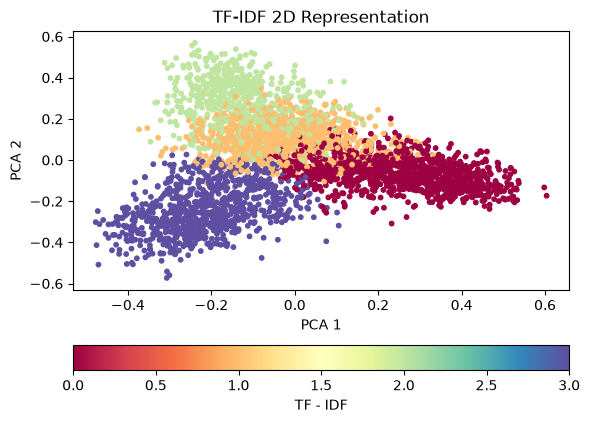

In [43]:
# [WRITE CODE]
from sklearn.decomposition import PCA

# Normalized 50-D document features from the preprocessing step.
X_reduced = Z
#####################################################################
# TODO:                                                             #
# Project X_reduced to 2D with PCA(n_components=2, random_state=RANDOM_STATE) and    #
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_2d = pca.fit_transform(X_reduced)
# scatter it, colored by cluster_labels (cmap='Spectral', small marker size).        #
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=cluster_labels, cmap='Spectral', s=10)
# Add a colorbar, title, and axis labels.                                           #
plt.title('TF-IDF 2D Representation')
plt.colorbar(label="TF - IDF", orientation="horizontal")  
plt.xlabel("PCA 1")  
plt.ylabel("PCA 2")   
plt.show()
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


### TODO 7 - UMAP to 2D

Do the same projection with `umap.UMAP(n_components=2, random_state=RANDOM_STATE)` (fixing the
seed - UMAP is stochastic otherwise) and color by the same cluster labels.

*If `import umap` fails, re-run the install cell at the top and restart the runtime.*

*UMAP with `metric="cosine"`, `n_neighbors=30`, `min_dist=0.1`.*

/home/ehorishny/miniconda3/envs/temp/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


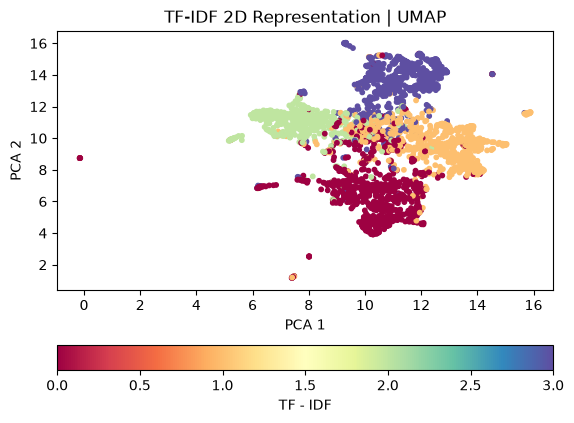

In [42]:
# [WRITE CODE]
import umap
#####################################################################
# TODO:                                                             #
# Project X_reduced to 2D with:                                                     #
pca_umap = umap.UMAP(n_components=2, random_state=RANDOM_STATE,metric="cosine", n_neighbors=30, min_dist=0.1)                         #
# Scatter it colored by cluster_labels, matching your PCA plot styling.  
umap_2d = pca_umap.fit_transform(X_reduced)
plt.scatter(umap_2d[:, 0], umap_2d[:, 1], c=cluster_labels, cmap='Spectral', s=10)
plt.title('TF-IDF 2D Representation | UMAP')
plt.colorbar(label="TF - IDF", orientation="horizontal")  
plt.xlabel("PCA 1")  
plt.ylabel("PCA 2")   
plt.show()           #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


### Quantifying the two embeddings

The cell below reports two diagnostics: **trustworthiness** (how well
each 2-D layout preserves the local neighborhoods of the 50-D features) and the **silhouette** of
the fixed K-Means labels in each 2-D plot (how compact/separated those groups look). Use the
numbers to answer the questions that follow.

In [ ]:
# [RUN ONLY]
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score

# Reuse the results computed earlier:
# X_reduced: normalized 50D SVD features
# pca_2d:    PCA coordinates computed from X_reduced
# umap_2d:   UMAP coordinates computed from X_reduced
# cluster_labels: one shared set of K-means assignments

assert (
    len(X_reduced)
    == len(pca_2d)
    == len(umap_2d)
    == len(cluster_labels)
)

# --- 1. Neighborhood preservation ---
# Evaluate each embedding relative to the SAME input representation.
# Higher trustworthiness means fewer unexpected neighbors in 2D.
tw_pca = trustworthiness(
    X_reduced,
    pca_2d,
    n_neighbors=15,
    metric="cosine",
)

tw_umap = trustworthiness(
    X_reduced,
    umap_2d,
    n_neighbors=15,
    metric="cosine",
)

# --- 2. Separation of the shared K-means groups in each 2D plot ---
# Reuse the SAME cluster labels for both embeddings.
# We are NOT fitting a new clustering in either 2D space.
sil_pca = silhouette_score(
    pca_2d,
    cluster_labels,
    metric="euclidean",
)

sil_umap = silhouette_score(
    umap_2d,
    cluster_labels,
    metric="euclidean",
)

# --- Summary ---
print(f'{"Metric":<38} | {"PCA (2D)":>12} | {"UMAP (2D)":>12}')
print("-" * 70)
print(
    f'{"Trustworthiness vs. SVD features":<38} | '
    f"{tw_pca:>12.4f} | {tw_umap:>12.4f}"
)
print(
    f'{"2D silhouette (fixed K-means labels)":<38} | '
    f"{sil_pca:>12.4f} | {sil_umap:>12.4f}"
)

**[ANSWER]**

### Question 3.1 - PCA vs. UMAP

Compare your two plots (both colored by K-Means cluster) and
explain *why* PCA and UMAP produce different structure.

*(Your answer here.)*

**[ANSWER]**

### Question 3.2 - Reading the diagnostics

* Which embedding has higher trustworthiness?
* In which embedding are the fixed K-Means groups more compact/separated by silhouette?
* Do the two metrics favor the same embedding?
* Why might an embedding preserve local neighborhoods well yet show lower separation of the fixed K-Means groups?
* Can we conclude that UMAP's visible groups correspond to the known newsgroup topics? Why or why not?

*(Your answer here.)*

# Part 4 - Open-Ended Interpretation  *(10%)*

K-Means never saw the true categories. Cluster ids are arbitrary (cluster "0" need not line up
with any category), so we first build a contingency table, then align clusters to categories by
**majority vote** and compute a purity score.

In [ ]:
# [WRITE CODE]
from scipy.stats import mode
#####################################################################
# TODO:                                                             #
# 1. Build a crosstab of true category (rows) vs cluster id (cols) and print it.     #
# 2. Map each cluster to its majority true label; compute                           #
#    purity = fraction of documents whose cluster-majority label == their true label.#
# 3. Print the cluster -> category mapping and the purity.                           #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


**[ANSWER]**

### Question 4.1 - What mixed, and why

Use the crosstab, the cluster → category mapping, and the purity score to answer:

* **Which categories are the cleanest** - i.e. mostly contained in a single cluster? Give the rough percentage of each that lands in its own cluster.
* **Which category is the leakiest** (most spread across clusters), and where do its stray documents go?
* **Which cluster acts as the oversized "catch-all"** that absorbs documents from several categories?
* **Explain *why* the mixing happens** in terms of vocabulary (what makes some categories separate cleanly while others get pooled).

*(Your answer here.)*

In [ ]:
# [RUN ONLY]
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix

# Rows correspond to clusters; columns correspond to true topics.
# Record the actual IDs rather than assuming they are consecutive.
cluster_ids = np.unique(cluster_labels)
topic_ids = np.unique(true_labels)

counts = contingency_matrix(cluster_labels, true_labels)

# Find the one-to-one cluster/topic matching with the largest overlap.
# Negating the counts lets us use a minimum-cost assignment.
cluster_rows, topic_cols = linear_sum_assignment(-counts)

# This comparison assumes equal numbers of clusters and topics.
assert len(cluster_ids) == len(topic_ids)

cluster_to_topic = {
    cluster_ids[row]: topic_ids[col]
    for row, col in zip(cluster_rows, topic_cols)
}

# Use these remapped IDs ONLY for plot coloring.
# Preserve cluster_labels for the original clustering results.
cluster_labels_for_color = np.array([
    cluster_to_topic[label]
    for label in cluster_labels
])

print("Cluster-to-topic matching used for colors:")
for cluster_id, topic_id in sorted(cluster_to_topic.items()):
    print(
        f"Cluster {cluster_id} → "
        f"Topic {topic_id}: {target_names[topic_id]}"
    )

### Visual check: K-Means colors vs. ground-truth topics

Run the cell below (it uses the matching from the previous cell). It draws PCA and UMAP, each
colored two ways: by K-Means (recolored to line up with topics) and by the true topic. Use it to
answer the questions that follow.

In [ ]:
# [RUN ONLY]
# Use identical color scaling in every panel.
vmin = topic_ids.min()
vmax = topic_ids.max()

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11),
    constrained_layout=True,
)

for row, (method, coordinates) in enumerate([
    ("PCA", pca_2d),
    ("UMAP", umap_2d),
]):
    for col, (colors, description) in enumerate([
        (
            cluster_labels_for_color,
            "K-means (colors aligned to topics)",
        ),
        (
            true_labels,
            "Ground-truth topics",
        ),
    ]):
        ax = axes[row, col]

        sc = ax.scatter(
            coordinates[:, 0],
            coordinates[:, 1],
            c=colors,
            cmap="Spectral",
            vmin=vmin,
            vmax=vmax,
            s=6,
        )

        ax.set_title(f"{method} — {description}")
        ax.set_xlabel("PC 1" if method == "PCA" else "UMAP 1")
        ax.set_ylabel("PC 2" if method == "PCA" else "UMAP 2")

cbar = fig.colorbar(
    sc,
    ax=axes.ravel().tolist(),
    ticks=topic_ids,
    shrink=0.8,
)

cbar.set_ticklabels([
    target_names[topic_id]
    for topic_id in topic_ids
])
cbar.set_label("Topic / matched cluster color")

plt.show()

**[ANSWER]**

### Question 4.2 - K-Means vs. ground truth

* For both PCA and UMAP, compare the left column (K-Means, recolored to topics) with the right
  column (true topics). How similar are the two colorings?
* What does that similarity tell you about how well K-Means recovered the newsgroup topics?
* Where do the two colorings disagree, and which topics are involved?

*(Your answer here.)*